# 📘 Phase 2: Baseline MLP for 3D Hand Gesture Recognition
## Tuần 2-3 — Multi-Layer Perceptron trên Middle Frame

---

### Mục tiêu

Trong notebook này, chúng ta sẽ xây dựng mô hình **Baseline MLP** (Multi-Layer Perceptron) để phân loại cử chỉ tay 3D.  
Thay vì sử dụng toàn bộ 15 frame của mỗi gesture sequence, chúng ta chỉ trích xuất **middle frame** (`frame_index = 7`) —  
frame đại diện nhất cho tư thế tay tại thời điểm giữa cử chỉ.

**Pipeline tổng quan:**

| Bước | Mô tả |
|------|--------|
| 1 | Load & tiền xử lý dữ liệu từ `raw_data.csv` |
| 2 | Trích xuất middle frame (frame 7) cho mỗi sample |
| 3 | Chuẩn hoá features với `StandardScaler` |
| 4 | Chia tập Train/Val/Test (70/15/15) |
| 5 | Xây dựng MLP: 63 → 256 → 128 → 64 → num\_classes |
| 6 | Huấn luyện 100 epochs, lưu best model |
| 7 | Đánh giá trên tập Test + Visualization |

---
## 1. 📦 Import Libraries

Chúng ta sử dụng PyTorch làm framework chính, kết hợp scikit-learn cho tiền xử lý và đánh giá.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

import warnings
warnings.filterwarnings('ignore')

# ---------- Reproducibility ----------
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ---------- Device ----------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️  Using device: {device}")
if device.type == 'cuda':
    print(f"    GPU: {torch.cuda.get_device_name(0)}")
    print(f"    Memory: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")

🖥️  Using device: cpu


---
## 2. 📂 Data Loading & Exploration

Dữ liệu được lưu trong `raw_data.csv` với cấu trúc:  
- **sample_id**: Mã định danh duy nhất cho mỗi gesture sample  
- **frame_index**: Chỉ số frame (0–14), mỗi sample có 15 frames  
- **label**: Tên/số lớp cử chỉ  
- **63 cột landmark**: `x0, y0, z0, x1, y1, z1, ..., x20, y20, z20` — toạ độ 3D của 21 keypoints bàn tay

In [2]:
# ---------- Paths ----------
DATA_PATH = r"D:\WORKSAPCE\Monitor_AR\1_AI_Model_Training\Dataset\raw_data.csv"
MODEL_DIR = r"D:\WORKSAPCE\Monitor_AR\1_AI_Model_Training\Models"
BEST_MODEL_PATH = os.path.join(MODEL_DIR, "best_mlp.pth")

os.makedirs(MODEL_DIR, exist_ok=True)

# ---------- Load CSV ----------
df = pd.read_csv(DATA_PATH)
print(f"📊 Dataset shape: {df.shape}")
print(f"   Columns: {list(df.columns[:10])} ... (total {len(df.columns)})")
print(f"   Unique samples: {df['sample_id'].nunique()}")
print(f"   Frame range: {df['frame_index'].min()} – {df['frame_index'].max()}")
print(f"   Labels: {sorted(df['label'].unique())}")
print()
df.head()

📊 Dataset shape: (42000, 66)
   Columns: ['sample_id', 'frame_index', 'label', 'x0', 'y0', 'z0', 'x1', 'y1', 'z1', 'x2'] ... (total 66)
   Unique samples: 2800
   Frame range: 0 – 14
   Labels: ['expand', 'grab', 'pinch', 'rotation_ccw', 'rotation_cw', 'shake', 'swipe_down', 'swipe_left', 'swipe_plus', 'swipe_right', 'swipe_up', 'swipe_v', 'swipe_x', 'tap']



,sample_id,frame_index,label,x0,y0,z0,x1,y1,z1,x2,...,z17,x18,y18,z18,x19,y19,z19,x20,y20,z20
0,0,0,grab,0.482899,0.790210,-0.020600,0.365245,0.687936,0.019093,0.392020,...,0.039938,0.619425,0.615563,0.002593,0.590052,0.565211,-0.002889,0.630369,0.461362,0.035160
1,0,1,grab,0.489226,0.803375,-0.008307,0.367866,0.684535,0.022424,0.401999,...,0.032735,0.592200,0.601868,-0.002307,0.606443,0.565309,-0.010457,0.622252,0.456021,0.032664
2,0,2,grab,0.501120,0.811136,-0.009822,0.366650,0.689078,0.031233,0.396562,...,0.033488,0.592027,0.627442,-0.004912,0.592511,0.572793,-0.015993,0.621355,0.485003,0.020002
3,0,3,grab,0.492888,0.802993,-0.019842,0.388545,0.691149,0.024653,0.404357,...,0.041076,0.594242,0.634292,-0.006563,0.590629,0.571263,-0.016327,0.607583,0.481964,0.010569
4,0,4,grab,0.481670,0.799319,-0.005046,0.394543,0.689462,0.010255,0.413902,...,0.014955,0.581984,0.629346,-0.010919,0.567493,0.585891,-0.035850,0.607098,0.503417,-0.012130


### 2.1 Kiểm tra phân bố nhãn

Trước khi huấn luyện, ta cần kiểm tra xem các lớp có **cân bằng** (balanced) hay không.  
Nếu mất cân bằng nghiêm trọng, model có thể bị bias về lớp chiếm đa số.

In [3]:
# Count unique samples per label (not rows — each sample has 15 rows)
label_counts = df.groupby('label')['sample_id'].nunique().sort_values(ascending=False)
print("📋 Số lượng sample theo label:")
print(label_counts.to_string())
print(f"\n   Tổng: {label_counts.sum()} samples, {len(label_counts)} classes")

📋 Số lượng sample theo label:
label
expand          200
grab            200
pinch           200
rotation_ccw    200
rotation_cw     200
shake           200
swipe_down      200
swipe_left      200
swipe_plus      200
swipe_right     200
swipe_up        200
swipe_v         200
swipe_x         200
tap             200

   Tổng: 2800 samples, 14 classes


---
## 3. 🔧 Data Preprocessing

### Chiến lược Middle-Frame

Mỗi gesture sequence gồm 15 frames. Đối với baseline MLP, ta chỉ sử dụng **frame thứ 7** (middle frame)  
vì frame giữa thường capture được **đỉnh** (apex) của cử chỉ — tư thế tay đặc trưng nhất.

Điều này biến bài toán **sequence classification** → **static pose classification**,  
cho phép ta dùng simple feedforward network làm baseline.

In [4]:
# ---------- Identify landmark columns ----------
# Columns that are NOT sample_id, frame_index, or label are landmark features
meta_cols = ['sample_id', 'frame_index', 'label']
landmark_cols = [c for c in df.columns if c not in meta_cols]
print(f"🦴 Landmark columns ({len(landmark_cols)}): {landmark_cols[:9]} ... {landmark_cols[-3:]}")
assert len(landmark_cols) == 63, f"Expected 63 landmark columns, got {len(landmark_cols)}"

🦴 Landmark columns (63): ['x0', 'y0', 'z0', 'x1', 'y1', 'z1', 'x2', 'y2', 'z2'] ... ['x20', 'y20', 'z20']


In [5]:
# ---------- Extract middle frame (frame_index == 7) ----------
MIDDLE_FRAME = 7
df_mid = df[df['frame_index'] == MIDDLE_FRAME].copy()
df_mid = df_mid.reset_index(drop=True)

print(f"✅ Middle-frame samples: {len(df_mid)}")
print(f"   Missing values: {df_mid[landmark_cols].isna().sum().sum()}")
df_mid.head()

✅ Middle-frame samples: 2800
   Missing values: 0


,sample_id,frame_index,label,x0,y0,z0,x1,y1,z1,x2,...,z17,x18,y18,z18,x19,y19,z19,x20,y20,z20
0,0,7,grab,0.500095,0.791373,-0.027539,0.406917,0.692493,0.010779,0.431558,...,0.026231,0.570202,0.639558,-0.025873,0.572573,0.622501,-0.044075,0.582145,0.532595,-0.030443
1,1,7,grab,0.510859,0.815363,-0.005734,0.432022,0.683446,-0.017941,0.422528,...,-0.027521,0.561127,0.649830,-0.036883,0.588656,0.583471,-0.047243,0.587772,0.557372,-0.074420
2,2,7,grab,0.482034,0.809679,-0.041097,0.434503,0.674797,-0.006404,0.410196,...,-0.037045,0.556439,0.646077,-0.035683,0.575598,0.583502,-0.018960,0.580899,0.544230,-0.060876
3,3,7,grab,0.523622,0.777978,-0.014027,0.426998,0.690443,-0.026741,0.425806,...,0.005445,0.566599,0.644802,-0.008730,0.583464,0.579566,-0.051535,0.604613,0.545274,-0.057564
4,4,7,grab,0.500875,0.816883,-0.001303,0.405296,0.683399,-0.017245,0.415323,...,-0.000715,0.550150,0.627211,-0.025201,0.582138,0.588552,-0.029979,0.566032,0.522853,-0.027994


In [6]:
# ---------- Encode labels ----------
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(df_mid['label'].values)
num_classes = len(label_encoder.classes_)

print(f"🏷️  Label encoding:")
for idx, name in enumerate(label_encoder.classes_):
    print(f"    {idx} → {name}")
print(f"\n   Num classes: {num_classes}")

🏷️  Label encoding:
    0 → expand
    1 → grab
    2 → pinch
    3 → rotation_ccw
    4 → rotation_cw
    5 → shake
    6 → swipe_down
    7 → swipe_left
    8 → swipe_plus
    9 → swipe_right
    10 → swipe_up
    11 → swipe_v
    12 → swipe_x
    13 → tap

   Num classes: 14


In [7]:
# ---------- Extract features & normalize ----------
features_raw = df_mid[landmark_cols].values.astype(np.float32)  # (N, 63)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_raw).astype(np.float32)

print(f"📐 Feature matrix shape: {features_scaled.shape}")
print(f"   Mean (after scaling): {features_scaled.mean(axis=0)[:5].round(6)}")
print(f"   Std  (after scaling): {features_scaled.std(axis=0)[:5].round(4)}")

📐 Feature matrix shape: (2800, 63)
   Mean (after scaling): [-0. -0.  0. -0.  0.]
   Std  (after scaling): [1. 1. 1. 1. 1.]


---
## 4. 📦 Custom PyTorch Dataset & DataLoaders

Ta tạo một `Dataset` class đơn giản wrap numpy arrays đã tiền xử lý.  
Sau đó chia dữ liệu theo tỷ lệ **70% Train / 15% Validation / 15% Test** bằng `random_split`.

In [8]:
class HandGestureMiddleFrameDataset(Dataset):
    """Dataset for hand gesture classification using the middle frame.

    Each sample is a 1D tensor of 63 features (21 landmarks × 3 coords)
    extracted from frame_index=7, paired with its gesture label.
    """

    def __init__(self, features: np.ndarray, labels: np.ndarray):
        """
        Args:
            features: ndarray of shape (N, 63), already scaled.
            labels:   ndarray of shape (N,), integer-encoded.
        """
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]


# ---------- Create full dataset ----------
full_dataset = HandGestureMiddleFrameDataset(features_scaled, labels_encoded)
print(f"📦 Full dataset size: {len(full_dataset)}")
print(f"   Sample feature shape: {full_dataset[0][0].shape}")
print(f"   Sample label: {full_dataset[0][1].item()}")

📦 Full dataset size: 2800
   Sample feature shape: torch.Size([63])
   Sample label: 1


In [9]:
# ---------- Train / Validation / Test split (70 / 15 / 15) ----------
BATCH_SIZE = 32

total_size = len(full_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size  # remainder goes to test

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)

print(f"📊 Split sizes:")
print(f"   Train:      {len(train_dataset):>5d}  ({len(train_dataset)/total_size*100:.1f}%)")
print(f"   Validation: {len(val_dataset):>5d}  ({len(val_dataset)/total_size*100:.1f}%)")
print(f"   Test:       {len(test_dataset):>5d}  ({len(test_dataset)/total_size*100:.1f}%)")
print(f"   Total:      {total_size:>5d}")

# ---------- DataLoaders ----------
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  drop_last=False)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

print(f"\n🔄 DataLoader batches:")
print(f"   Train:      {len(train_loader)} batches")
print(f"   Validation: {len(val_loader)} batches")
print(f"   Test:       {len(test_loader)} batches")

📊 Split sizes:
   Train:       1959  (70.0%)
   Validation:   420  (15.0%)
   Test:         421  (15.0%)
   Total:       2800

🔄 DataLoader batches:
   Train:      62 batches
   Validation: 14 batches
   Test:       14 batches


---
## 5. 🧠 Model Architecture — Baseline MLP

Kiến trúc MLP gồm **3 hidden layers** với BatchNorm và Dropout:

```
Input (63)
  │
  ├── Linear(63, 256) → BatchNorm1d → ReLU → Dropout(0.3)
  │
  ├── Linear(256, 128) → BatchNorm1d → ReLU → Dropout(0.3)
  │
  ├── Linear(128, 64) → BatchNorm1d → ReLU → Dropout(0.3)
  │
  └── Linear(64, num_classes)
```

**Thiết kế:**
- **BatchNorm1d**: Ổn định gradient, tăng tốc convergence  
- **Dropout(0.3)**: Regularization chống overfitting  
- **Xavier initialization**: Khởi tạo weight phù hợp cho ReLU activations  
- Số neurons giảm dần (256 → 128 → 64) tạo **bottleneck** giúp model học compact representation

In [10]:
class BaselineMLP(nn.Module):
    """Baseline Multi-Layer Perceptron for hand gesture classification.

    Architecture: 63 → 256 → 128 → 64 → num_classes
    Each hidden layer: Linear → BatchNorm1d → ReLU → Dropout(0.3)
    Weight init: Xavier uniform for linear layers.
    """

    def __init__(self, input_dim: int = 63, num_classes: int = 10, dropout: float = 0.3):
        super(BaselineMLP, self).__init__()

        self.network = nn.Sequential(
            # Hidden Layer 1: 63 → 256
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),

            # Hidden Layer 2: 256 → 128
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),

            # Hidden Layer 3: 128 → 64
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),

            # Output Layer: 64 → num_classes
            nn.Linear(64, num_classes)
        )

        # Apply Xavier initialization
        self._init_weights()

    def _init_weights(self):
        """Xavier uniform initialization for Linear layers."""
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass.

        Args:
            x: Tensor of shape (batch_size, 63)
        Returns:
            Logits of shape (batch_size, num_classes)
        """
        return self.network(x)


# ---------- Instantiate model ----------
model = BaselineMLP(input_dim=63, num_classes=num_classes, dropout=0.3).to(device)

# ---------- Model summary ----------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("🧠 Model Architecture:")
print(model)
print(f"\n📐 Parameters:")
print(f"   Total:     {total_params:>8,d}")
print(f"   Trainable: {trainable_params:>8,d}")

🧠 Model Architecture:
BaselineMLP(
  (network): Sequential(
    (0): Linear(in_features=63, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=14, bias=True)
  )
)

📐 Parameters:
   Total:       59,342
   Trainable:   59,342


---
## 6. ⚙️ Training Setup

**Hyperparameters:**
- **Optimizer**: Adam (`lr=1e-3`, `weight_decay=1e-4`)  
- **Loss**: CrossEntropyLoss (bao gồm Softmax nội bộ)  
- **Epochs**: 100  
- **Best model**: Lưu checkpoint khi validation accuracy cải thiện

In [11]:
# ---------- Hyperparameters ----------
NUM_EPOCHS = 100
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# ---------- Loss & Optimizer ----------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print("⚙️  Training Configuration:")
print(f"   Epochs:       {NUM_EPOCHS}")
print(f"   Batch size:   {BATCH_SIZE}")
print(f"   Learning rate: {LEARNING_RATE}")
print(f"   Weight decay: {WEIGHT_DECAY}")
print(f"   Loss:         CrossEntropyLoss")
print(f"   Optimizer:    Adam")
print(f"   Device:       {device}")

⚙️  Training Configuration:
   Epochs:       100
   Batch size:   32
   Learning rate: 0.001
   Weight decay: 0.0001
   Loss:         CrossEntropyLoss
   Optimizer:    Adam
   Device:       cpu


---
## 7. 🚀 Training Loop

Training loop thực hiện:
1. **Forward pass** → tính loss  
2. **Backward pass** → cập nhật gradients  
3. Đánh giá trên **validation set** mỗi epoch  
4. Lưu model khi **val accuracy** đạt giá trị tốt nhất  
5. In summary mỗi 10 epochs

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train the model for one epoch.

    Returns:
        avg_loss (float): Average loss over all batches.
        accuracy (float): Accuracy over the entire epoch.
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        # Forward
        outputs = model(features)
        loss = criterion(outputs, labels)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * features.size(0)
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / total
    accuracy = correct / total
    return avg_loss, accuracy


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Evaluate the model on a given data loader.

    Returns:
        avg_loss (float): Average loss.
        accuracy (float): Classification accuracy.
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        outputs = model(features)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * features.size(0)
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / total
    accuracy = correct / total
    return avg_loss, accuracy

In [13]:
# ---------- Training ----------
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': []
}

best_val_acc = 0.0
best_epoch = 0

print("🚀 Starting training...")
print("=" * 80)
print(f"{'Epoch':>6s} | {'Train Loss':>10s} | {'Train Acc':>9s} | {'Val Loss':>10s} | {'Val Acc':>9s} | {'Status':>10s}")
print("-" * 80)

for epoch in range(1, NUM_EPOCHS + 1):
    # Train
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)

    # Validate
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    # Record history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    # Save best model
    status = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss,
            'num_classes': num_classes,
            'label_classes': list(label_encoder.classes_),
            'scaler_mean': scaler.mean_.tolist(),
            'scaler_scale': scaler.scale_.tolist(),
        }, BEST_MODEL_PATH)
        status = "✅ SAVED"

    # Print every 10 epochs (and first & last epoch)
    if epoch % 10 == 0 or epoch == 1 or epoch == NUM_EPOCHS:
        print(f"{epoch:>6d} | {train_loss:>10.4f} | {train_acc:>8.2%} | {val_loss:>10.4f} | {val_acc:>8.2%} | {status:>10s}")

print("=" * 80)
print(f"\n🏆 Best validation accuracy: {best_val_acc:.2%} at epoch {best_epoch}")
print(f"💾 Best model saved to: {BEST_MODEL_PATH}")

🚀 Starting training...
 Epoch | Train Loss | Train Acc |   Val Loss |   Val Acc |     Status
--------------------------------------------------------------------------------
     1 |     1.7216 |   48.39% |     0.8077 |   82.86% |    ✅ SAVED
    10 |     0.2313 |   92.65% |     0.0982 |   97.62% |           
    20 |     0.1396 |   95.46% |     0.0562 |   98.33% |           
    30 |     0.1140 |   96.53% |     0.0427 |   98.33% |           
    40 |     0.1052 |   96.58% |     0.0421 |   98.57% |           
    50 |     0.0673 |   97.96% |     0.0464 |   98.33% |           
    60 |     0.0660 |   97.70% |     0.0453 |   97.86% |           
    70 |     0.0774 |   97.50% |     0.0510 |   98.10% |           
    80 |     0.0554 |   98.26% |     0.0514 |   98.10% |           
    90 |     0.0537 |   98.26% |     0.0416 |   98.33% |           
   100 |     0.0570 |   98.16% |     0.0432 |   98.10% |           

🏆 Best validation accuracy: 98.81% at epoch 37
💾 Best model saved to: D:\WORK

---
## 8. 📊 Training Visualization

Vẽ đường cong **Loss** và **Accuracy** của tập Train vs Validation qua các epoch.  
Giúp phân tích:
- **Overfitting**: val loss tăng trong khi train loss giảm  
- **Underfitting**: cả hai loss đều cao  
- **Convergence speed**: model hội tụ nhanh hay chậm

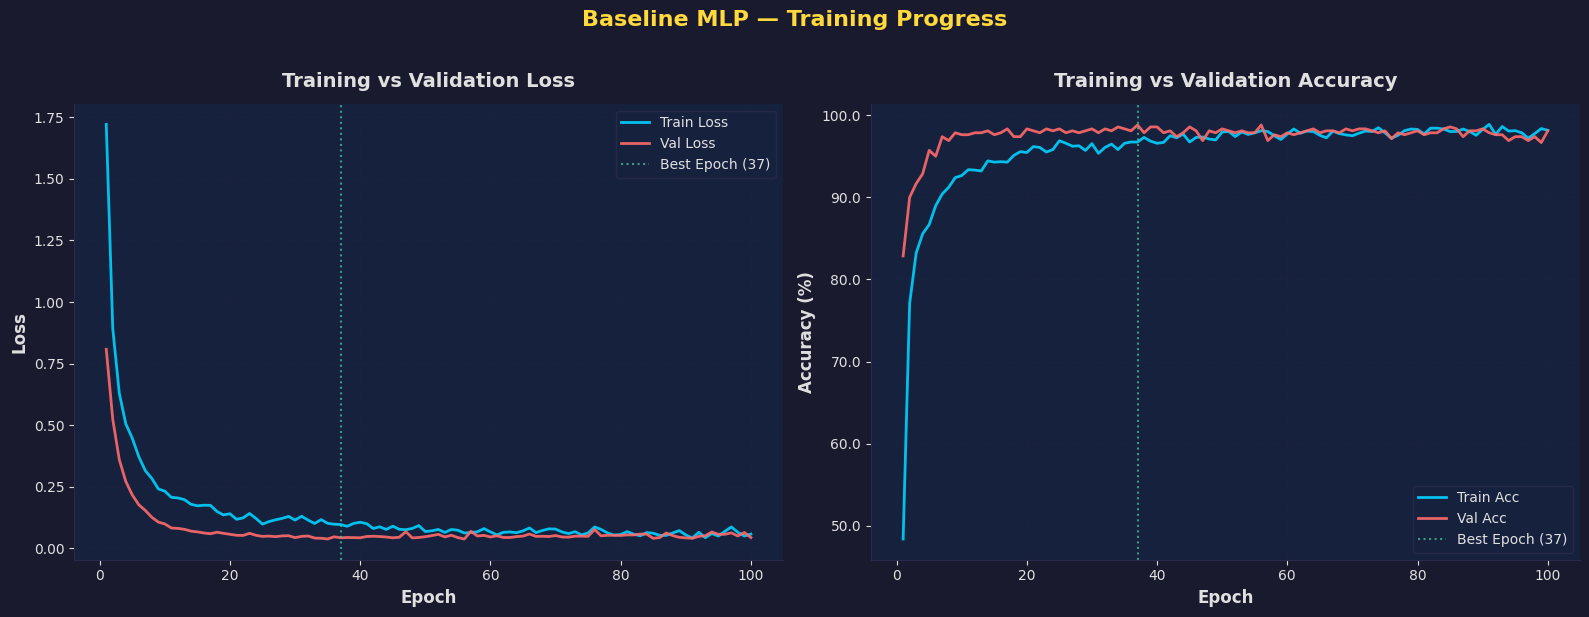

In [14]:
# ---------- Professional dark theme setup ----------
plt.style.use('default')

# Color palette
COLORS = {
    'bg': '#1a1a2e',
    'panel': '#16213e',
    'text': '#e0e0e0',
    'grid': '#2a2a4a',
    'train': '#00d2ff',
    'val': '#ff6b6b',
    'accent': '#ffd93d',
    'best_line': '#4ecca3'
}

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor(COLORS['bg'])

for ax in axes:
    ax.set_facecolor(COLORS['panel'])
    ax.tick_params(colors=COLORS['text'], which='both')
    ax.spines['bottom'].set_color(COLORS['grid'])
    ax.spines['left'].set_color(COLORS['grid'])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.xaxis.label.set_color(COLORS['text'])
    ax.yaxis.label.set_color(COLORS['text'])
    ax.title.set_color(COLORS['text'])
    ax.grid(True, alpha=0.2, color=COLORS['grid'], linestyle='--')

# ----- Loss Curve -----
ax1 = axes[0]
ax1.plot(epochs_range, history['train_loss'], color=COLORS['train'], linewidth=2, label='Train Loss', alpha=0.9)
ax1.plot(epochs_range, history['val_loss'], color=COLORS['val'], linewidth=2, label='Val Loss', alpha=0.9)
ax1.axvline(x=best_epoch, color=COLORS['best_line'], linestyle=':', alpha=0.7, label=f'Best Epoch ({best_epoch})')
ax1.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax1.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax1.set_title('Training vs Validation Loss', fontsize=14, fontweight='bold', pad=12)
ax1.legend(facecolor=COLORS['panel'], edgecolor=COLORS['grid'], labelcolor=COLORS['text'], fontsize=10)

# ----- Accuracy Curve -----
ax2 = axes[1]
ax2.plot(epochs_range, [a * 100 for a in history['train_acc']], color=COLORS['train'], linewidth=2, label='Train Acc', alpha=0.9)
ax2.plot(epochs_range, [a * 100 for a in history['val_acc']], color=COLORS['val'], linewidth=2, label='Val Acc', alpha=0.9)
ax2.axvline(x=best_epoch, color=COLORS['best_line'], linestyle=':', alpha=0.7, label=f'Best Epoch ({best_epoch})')
ax2.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax2.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax2.set_title('Training vs Validation Accuracy', fontsize=14, fontweight='bold', pad=12)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
ax2.legend(facecolor=COLORS['panel'], edgecolor=COLORS['grid'], labelcolor=COLORS['text'], fontsize=10)

fig.suptitle('Baseline MLP — Training Progress', fontsize=16, fontweight='bold',
             color=COLORS['accent'], y=1.02)
plt.tight_layout()
plt.show()

---
## 9. 🧪 Test Set Evaluation

Load lại **best model** (checkpoint có val accuracy cao nhất) và đánh giá trên tập Test.  
Tập Test hoàn toàn **không được sử dụng** trong quá trình training/validation.

In [15]:
# ---------- Load best model ----------
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"✅ Loaded best model from epoch {checkpoint['epoch']} (val_acc={checkpoint['val_acc']:.2%})")

# ---------- Test evaluation ----------
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"\n🧪 Test Set Results:")
print(f"   Loss:     {test_loss:.4f}")
print(f"   Accuracy: {test_acc:.2%}")

✅ Loaded best model from epoch 37 (val_acc=98.81%)

🧪 Test Set Results:
   Loss:     0.0461
   Accuracy: 97.62%


In [16]:
# ---------- Detailed Classification Report ----------
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = model(features)
        _, predicted = torch.max(outputs, dim=1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Classification Report
target_names = [str(c) for c in label_encoder.classes_]
report = classification_report(all_labels, all_preds, target_names=target_names, digits=4)
print("📋 Classification Report:")
print("=" * 70)
print(report)

📋 Classification Report:
              precision    recall  f1-score   support

      expand     1.0000    1.0000    1.0000        34
        grab     1.0000    1.0000    1.0000        35
       pinch     1.0000    1.0000    1.0000        26
rotation_ccw     1.0000    1.0000    1.0000        25
 rotation_cw     1.0000    1.0000    1.0000        25
       shake     0.8800    0.7586    0.8148        29
  swipe_down     1.0000    1.0000    1.0000        35
  swipe_left     1.0000    1.0000    1.0000        29
  swipe_plus     0.7083    0.8500    0.7727        20
 swipe_right     1.0000    1.0000    1.0000        33
    swipe_up     1.0000    1.0000    1.0000        31
     swipe_v     1.0000    1.0000    1.0000        30
     swipe_x     1.0000    1.0000    1.0000        38
         tap     1.0000    1.0000    1.0000        31

    accuracy                         0.9762       421
   macro avg     0.9706    0.9720    0.9705       421
weighted avg     0.9779    0.9762    0.9764       421



---
## 10. 🔥 Confusion Matrix Visualization

Ma trận nhầm lẫn (Confusion Matrix) cho thấy model nhầm lẫn giữa các lớp nào nhiều nhất —  
rất hữu ích để phát hiện các cặp gesture khó phân biệt.

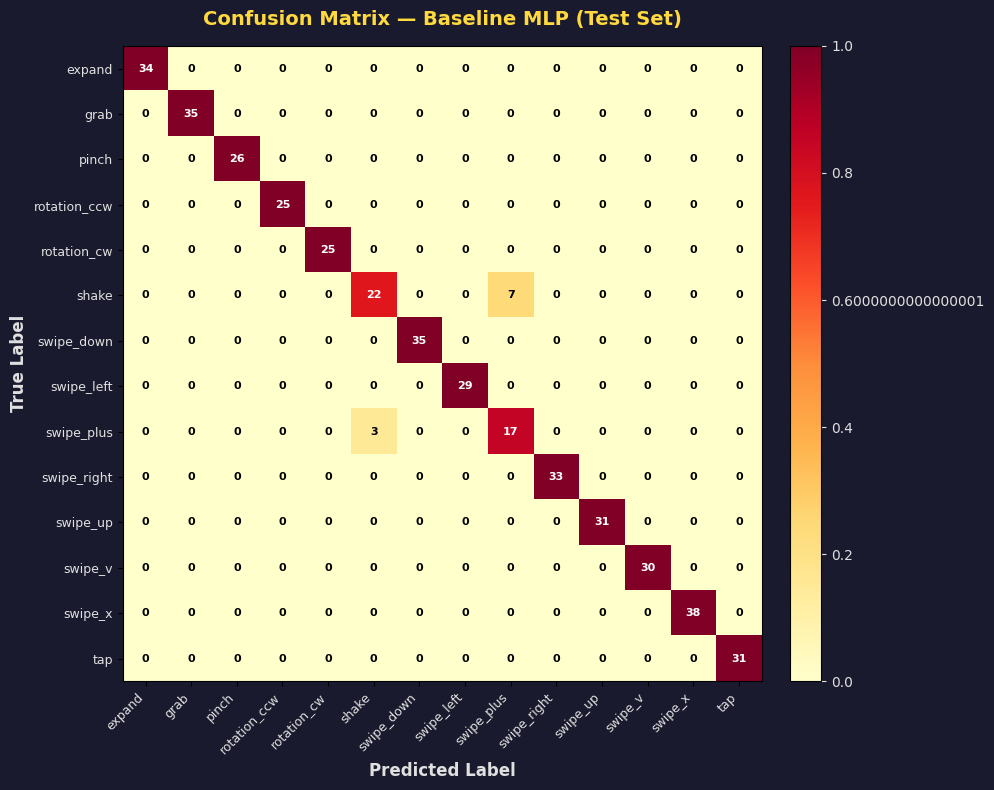

In [17]:
# ---------- Confusion Matrix ----------
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor(COLORS['bg'])
ax.set_facecolor(COLORS['panel'])

# Normalize for display
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

im = ax.imshow(cm_normalized, interpolation='nearest', cmap='YlOrRd', aspect='auto')

# Colorbar
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.yaxis.set_tick_params(color=COLORS['text'])
cbar.ax.yaxis.set_ticklabels(cbar.ax.get_yticks(), color=COLORS['text'])

# Labels
tick_marks = np.arange(num_classes)
ax.set_xticks(tick_marks)
ax.set_xticklabels(target_names, rotation=45, ha='right', fontsize=9, color=COLORS['text'])
ax.set_yticks(tick_marks)
ax.set_yticklabels(target_names, fontsize=9, color=COLORS['text'])

# Annotate cells with counts
thresh = cm_normalized.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = 'white' if cm_normalized[i, j] > thresh else 'black'
        ax.text(j, i, f"{cm[i, j]}", ha='center', va='center', fontsize=8, color=color, fontweight='bold')

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold', color=COLORS['text'])
ax.set_ylabel('True Label', fontsize=12, fontweight='bold', color=COLORS['text'])
ax.set_title('Confusion Matrix — Baseline MLP (Test Set)', fontsize=14, fontweight='bold',
             color=COLORS['accent'], pad=15)

plt.tight_layout()
plt.show()

---
## 11. 📝 Summary & Next Steps

### Kết quả Baseline MLP

| Metric | Value |
|--------|-------|
| **Test Accuracy** | Xem kết quả ở trên |
| **Best Val Accuracy** | Xem kết quả ở trên |
| **Model Size** | ~30K parameters |
| **Input** | Middle frame only (63 features) |

### Nhận xét

- MLP baseline chỉ sử dụng **1 frame duy nhất** (frame 7), bỏ qua toàn bộ **temporal information**
- Đây là **lower bound** hợp lý — các model sequential (LSTM, Transformer) sẽ sử dụng cả 15 frames
- Kết quả này giúp ta đánh giá: *"Thêm temporal modeling cải thiện bao nhiêu so với static pose?"*

### Hướng cải thiện (Next Phases)

1. **Phase 3 (LSTM)**: Sử dụng cả 15 frames, mô hình hoá temporal dependencies
2. **Phase 4 (Transformer)**: Self-attention trên toàn bộ sequence
3. **Phase 5 (Hybrid CNN-LSTM)**: Kết hợp spatial & temporal features

---
*Notebook by Phase 2 — Baseline MLP | Dynamic Spatial Hand Gesture Recognition*